intro_to_Language_modeling part3 -

[viedo link](https://youtu.be/P6sfmUTpUmc)

<u>**Model Structure**</u>

Input = 3-character context (as indices)

Hidden layer = 1 layer with 200 neurons

Output = prediction of the next character (as 1 of 27 logits)

<u>**Activation functions**</u>

Hidden layer : tahn - The hidden layer uses the tanh activation function to introduce non-linearity

Output layer : softmax(part of F.cross_entropy) - softmax is applied to logits to convert them into a probability distribution over the output characters


<u>**Goal**</u>

similar to earlier model you're training a neural network to predict the next character in a name based on a fixed-length context of previous characters

Additionally we do the following optimization
1. reducing initial (high) loss during training
2. fixing saturated tanh

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   319k      0 --:--:-- --:--:-- --:--:--  319k


In [3]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

Previous Neuralnet Revised
-------

same logic as previous(i.e part2) but refactored for readablity and performance

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# build the dataset for training,dev and test split
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% training split
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% dev split
Xte,  Yte  = build_dataset(words[n2:])     # 10% test split

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)
W2 = torch.randn((n_hidden, vocab_size),          generator=g)
b2 = torch.randn(vocab_size,                      generator=g)

# parameters
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [7]:
# Training the neuralnel - same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 27.8817
  10000/ 200000: 2.9692
  20000/ 200000: 2.5381
  30000/ 200000: 2.8408
  40000/ 200000: 2.0277
  50000/ 200000: 2.4590
  60000/ 200000: 2.4944
  70000/ 200000: 2.1338
  80000/ 200000: 2.4030
  90000/ 200000: 2.3502
 100000/ 200000: 2.0447
 110000/ 200000: 2.3922
 120000/ 200000: 1.9163
 130000/ 200000: 2.3493
 140000/ 200000: 2.2710
 150000/ 200000: 2.1671
 160000/ 200000: 2.0766
 170000/ 200000: 1.8112
 180000/ 200000: 2.0169
 190000/ 200000: 1.8818


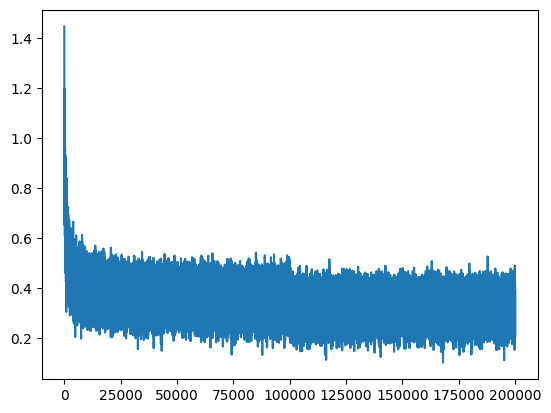

In [8]:
plt.plot(lossi)

In [9]:
# checking the train and val/dev loss
@torch.no_grad() # this decorator disables gradient tracking of pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  h = torch.tanh(embcat @ W1 + b1) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.124457836151123
val 2.1642823219299316


In [10]:
# sampling from neuralnet
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20): # generating 20 samples

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      # one sample index
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the contexxt window . eg '..e'
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0: # breaks the while loop on char '.'
        break

    print(''.join(itos[i] for i in out))

mora.
mayah.
seel.
nah.
yal.
ren.
ruchadrieg.
adelyn.
eliianni.
jen.
eden.
estanar.
kayzion.
kamin.
shubergshiriel.
kendreth.
konnie.
cayu.
zen.
dariyah.


Neuralnet optimization 01 - reducing initial loss
----------

We see that in previous section the initial loss during trainging was too high(i.e 27.8817)

**Why is initial loss too high?**

Model parameters (weights & biases) are randomly initialized and the first predictions are essentially random guesses. This leads to a high loss because the model's initial outputs are far from the correct target values.

**What is the expected as initial loss?**

Ideally, during the first training cycle, we would want our model to predict all 27 characters to have the same probability. This means we want the probabilities to be uniformly distributed among the 27 characters.

To achieve a uniformly distributed probability after the softmax activation, we would want all the logits (the raw outputs of the network before the softmax) to be roughly zero or the same value. This is because the softmax function, when applied to zero or equal logits, results in a uniform probability distribution.

The subsequent code cell implements the optimization of multiplying the W2 weights by 0.01 and setting the b2 biases to 0. This directly addresses the goal of making the initial logits closer to zero, thereby moving the initial predictions towards a more uniform distribution and reducing the initial loss

**Note:** The most effective way to make the initial logits close to zero and achieve a more uniform initial probability distribution is to directly adjust the parameters of the output layer (W2 and b2), which have a linear relationship with the logits

[link](https://youtu.be/P6sfmUTpUmc?list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&t=302)

**why we use 0.01 and not 0 for W2 ?**

1. Breaking Symmetry: If we were to initialize all weights in W2 to zero, the gradients for all neurons in the hidden layer would be the same during the first backward pass. This is because the gradient of the loss with respect to the hidden layer output (h) depends on W2. If W2 is all zeros, this gradient will be the same for all hidden neurons, leading to them learning the same features. This is known as the "symmetry breaking" problem. By initializing W2 with small random values (achieved by multiplying torch.randn by 0.01), we break this symmetry and allow different hidden neurons to learn different aspects of the input data.

2. Allowing for Learning: While we want the initial logits to be close to zero for a uniform probability distribution, we don't want them to be exactly zero all the time. A small non-zero value in W2 allows for slight variations in the initial logits based on the hidden layer output (h). This provides a starting point for the network to learn and adjust the weights during training. If W2 were all zeros, the initial logits would always be zero (assuming b2 is also zero), and the network would have difficulty learning meaningful relationships between the hidden layer and the output.

3. Small Initial Gradients: Multiplying W2 by a small value ensures that the initial gradients with respect to the hidden layer (h) and the parameters of the first layer (W1 and b1) are also small. This helps in preventing large updates to the parameters during the initial steps of training, which can sometimes lead to instability.

In summary, scaling W2 by a small non-zero value like 0.01 helps in breaking symmetry, allows the network to start learning, and contributes to more stable training in the initial stages, while still achieving the goal of having initial logits close to zero for a more uniform initial probability distribution


In [11]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)

# fixing the initial high loss
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 #here we multiply weights by 0.01. This is done to make the initial weights closer to zero, which helps in reducing the initial loss during training.
b2 = torch.randn(vocab_size,                      generator=g) * 0 #here we multiply biases by 0 to make all the biases to 0. This also contributes to making the initial logits (the raw output of the network before the softmax) closer to zero, leading to a more uniform initial probability distribution over the characters

# parameters
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [12]:
# Training the neuralnel - logic same as before
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break #just breaking after first loop, so that we see only the initial loss

      0/ 200000: 3.3221


In [13]:
#plt.plot(lossi)

Neuralnet optimization 02 - fixing saturated tanh
--------

In [14]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)
b1 = torch.randn(n_hidden,                        generator=g)

# adjusting W1 and b2 for fixing the initial high loss
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01 #here we multiply weights by 0.01. This is done to make the initial weights closer to zero, which helps in reducing the initial loss during training.
b2 = torch.randn(vocab_size,                      generator=g) * 0 #here we multiply biases by 0 to make all the biases to 0. This also contributes to making the initial logits (the raw output of the network before the softmax) closer to zero, leading to a more uniform initial probability distribution over the characters

# parameters
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

11897


In [15]:
# Training the neuralnel - logic same as before
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break #just breaking after first loop, so that we see only the initial loss

      0/ 200000: 3.3221
